# 04 · Interfaz web con Gradio (y base para el asistente)

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Materia:** Inteligencia Artificial (Ingeniería de Sistemas, FUP)

**Objetivo de la Fase 4:** llevar el sistema de la Fase 3 (Haar Cascade + CNN con TTA + suavizado + historial) a una **aplicación web local** que muestre:
1. El **video de la webcam en vivo** con el rostro detectado.
2. La **emoción actual** con su **confianza**.
3. El **panel de probabilidades** de las 7 emociones.
4. La **gráfica del historial** de emociones.

La interfaz queda con un espacio reservado para el **chat del asistente** (Fase 5, Chat 4).

**Estructura del notebook**
- **Parte 1:** importar el código de la Fase 3 desde el módulo `src/` y verificarlo.
- **Parte 2:** cómo funciona Gradio y las funciones que procesan cada cuadro.
- **Parte 3:** construir y lanzar la interfaz.
- **Parte 4:** resultados de la sesión (rendimiento e historial) y evidencias para el reporte.

> **Privacidad:** el video lo captura el navegador y lo envía solo a tu propio PC (`127.0.0.1`). Ningún cuadro se guarda en disco ni en este notebook: el cuadro anotado viaja al navegador codificado en memoria. Solo se guardan **etiquetas y números** (historial y métricas).

## Parte 1 · El código de la Fase 3 como módulo

En la Fase 3 las funciones vivían dentro del notebook `03`. Para usarlas aquí sin copiarlas y pegarlas, se movieron a **módulos de Python** (archivos `.py`) en la carpeta `src/`:

| Archivo | Qué contiene |
|---|---|
| `src/__init__.py` | Marca la carpeta `src` como **paquete** de Python (permite escribir `from src.… import …`). |
| `src/emotion_detection.py` | Clase `EmotionDetector` (carga el modelo y el Haar Cascade; `detect_faces`, `extract_face`, `predict` con `tf.function` + TTA, `analyze_frame`), `draw_results`, etiquetas y colores. |
| `src/emotion_tracking.py` | `EmotionSmoother` (media móvil, N = 10), `EmotionHistory` (1 muestra/s, `summary()`) y `count_label_changes`. |

**¿Por qué un módulo?**
- **Una sola fuente de verdad (principio DRY, *Don't Repeat Yourself*):** si se corrige algo, se corrige en un lugar y lo usan todos los notebooks.
- **Clase en lugar de funciones sueltas:** `EmotionDetector` carga el modelo **una vez** en su `__init__` y lo guarda como atributo (`self.model`). Así no dependemos de variables globales del notebook.
- **Cambio respecto a la Fase 3:** `analyze_frame()` recibe `color_order` (`"BGR"` u `"RGB"`), porque Gradio entrega los cuadros en **RGB** y OpenCV en **BGR** (se explica en la celda de verificación). `EmotionHistory` recibe la lista de clases al crearse.

**`sys.path`:** es la lista de carpetas donde Python busca los módulos al hacer `import`. Jupyter arranca en `notebooks/`, así que agregamos la **raíz del proyecto** para que encuentre `src/`.

> Si modificas un `.py` de `src/`, haz **Kernel → Restart Kernel** y vuelve a ejecutar: Python importa cada módulo una sola vez por sesión.

In [1]:
# Muestra las gráficas de Matplotlib dentro del notebook
%matplotlib inline

# --- Configuración ANTES de importar las librerías ---
import os
os.environ["GRADIO_ANALYTICS_ENABLED"] = "False"   # Gradio no envía estadísticas de uso a internet
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"           # oculta los mensajes informativos de TensorFlow

# --- Librerías ---
import sys
import json
import time
import base64              # convertir el cuadro JPEG a texto para mostrarlo en el navegador
import threading           # candado (Lock) para que dos eventos no modifiquen la sesión a la vez
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure   # figuras sin pyplot: seguras para usar desde Gradio (hilos)
from IPython.display import HTML, display
import tensorflow as tf
import keras
import gradio as gr

# --- Rutas: el notebook vive en notebooks/, la raíz del proyecto es la carpeta padre ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))           # para que Python encuentre la carpeta src/

# --- Código de la Fase 3, ahora importado desde src/ ---
from src.emotion_detection import EmotionDetector, draw_results, EMOTION_LABELS_ES, hex_color, FACE_SIZE
from src.emotion_tracking import EmotionSmoother, EmotionHistory, count_label_changes, SMOOTHING_WINDOW

print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__} | OpenCV: {cv2.__version__} | Gradio: {gr.__version__}")
print("Raíz del proyecto:", PROJECT_ROOT)

C:\Users\Personal\anaconda3\envs\emotion-ai\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TensorFlow: 2.21.0 | Keras: 3.15.1 | OpenCV: 4.14.0 | Gradio: 6.32.0
Raíz del proyecto: C:\Users\Personal\Projects\emotion-detection-assistant


In [2]:
# --- Crear el detector: carga el modelo, el Haar Cascade y compila la predicción rápida ---
start = time.perf_counter()
detector = EmotionDetector(MODELS_DIR)
CLASS_NAMES = detector.class_names

print(f"Modelo:  {detector.model_path.name} ({detector.model.count_params():,} parámetros)")
print(f"TTA:     {detector.use_tta}")
print(f"Clases:  {CLASS_NAMES}")
print(f"Listo en {time.perf_counter() - start:.1f} s (incluye compilar el grafo de tf.function)")

Modelo:  improved_model_v2.keras (5,872,455 parámetros)
TTA:     True
Clases:  ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Listo en 1.0 s (incluye compilar el grafo de tf.function)


### 1.1 Verificación del módulo

Antes de construir la interfaz, comprobamos que el código del módulo se comporta **igual que en la Fase 3**:
1. `detector.predict()` (con `tf.function` + TTA) da las **mismas probabilidades** que `model.predict()`.
2. Cada fila de probabilidades **suma 1** (salida softmax).
3. **RGB vs BGR:** una imagen a color tiene 3 canales, pero el orden cambia según la librería: OpenCV usa **B, G, R** y el navegador, Gradio y Matplotlib usan **R, G, B**. Para pasar a grises se usa la luminancia $Y = 0{,}299\,R + 0{,}587\,G + 0{,}114\,B$. Si se usa el código equivocado, el peso de 0,299 cae sobre el azul y el de 0,114 sobre el rojo, y el rostro en grises sale **distinto** al que el modelo vio en el entrenamiento. La prueba mide esa diferencia.
4. El tiempo de `analyze_frame()` en un cuadro de 640x480.

In [3]:
# 1) Mismas probabilidades que model.predict() con TTA (8 "rostros" aleatorios)
rng = np.random.default_rng(0)
faces = rng.integers(0, 256, size=(8, FACE_SIZE, FACE_SIZE)).astype(np.float32)
x = faces[..., np.newaxis]
reference = detector.model.predict(np.concatenate([x, x[:, :, ::-1, :]]), verbose=0)
reference = (reference[:8] + reference[8:]) / 2               # promedio original + espejo
module_probs = detector.predict(faces)
same = np.allclose(reference, module_probs, atol=1e-5)
print(f"{'✅' if same else '❌'} detector.predict() = model.predict() con TTA (máx. diferencia {np.abs(reference - module_probs).max():.1e})")

# 2) Las probabilidades suman 1
sums_ok = np.allclose(module_probs.sum(axis=1), 1, atol=1e-4)
print(f"{'✅' if sums_ok else '❌'} Cada fila suma 1 (ej.: {module_probs[0].sum():.4f})")

# 3) RGB vs BGR: el mismo cuadro convertido a grises con el código correcto y con el equivocado
frame_rgb = np.zeros((480, 640, 3), dtype=np.uint8)
frame_rgb[..., 0] = np.linspace(0, 255, 640, dtype=np.uint8)          # canal R: degradado horizontal
frame_rgb[..., 2] = np.linspace(255, 0, 480, dtype=np.uint8)[:, None]  # canal B: degradado vertical
gray_right = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
gray_wrong = cv2.cvtColor(frame_rgb, cv2.COLOR_BGR2GRAY)
diff = np.abs(gray_right.astype(int) - gray_wrong.astype(int))
print(f"ℹ️ RGB tratado como BGR: los grises cambian en promedio {diff.mean():.1f} niveles (máx. {diff.max()}) de 255"
      " → por eso analyze_frame() recibe color_order='RGB' con Gradio")

# 4) Tiempo de analyze_frame() en un cuadro de 640x480 sin rostro (solo detección)
blank = np.full((480, 640, 3), 90, dtype=np.uint8)
detector.analyze_frame(blank, color_order="RGB")                      # primera llamada (calentamiento)
times = [detector.analyze_frame(blank, color_order="RGB")[2]["detection_ms"] for _ in range(20)]
print(f"ℹ️ Detección Haar en 640x480: {np.mean(times):.1f} ms por cuadro (promedio de 20)")

✅ detector.predict() = model.predict() con TTA (máx. diferencia 0.0e+00)
✅ Cada fila suma 1 (ej.: 1.0000)
ℹ️ RGB tratado como BGR: los grises cambian en promedio 15.8 niveles (máx. 47) de 255 → por eso analyze_frame() recibe color_order='RGB' con Gradio
ℹ️ Detección Haar en 640x480: 5.0 ms por cuadro (promedio de 20)


## Parte 2 · Cómo funciona la interfaz con Gradio

### 2.1 Arquitectura cliente-servidor
**Gradio** es una librería que crea una **aplicación web** a partir de funciones de Python. Al lanzarla se levanta un **servidor web local** (`http://127.0.0.1:7860`; `127.0.0.1` significa "este mismo PC") y el navegador muestra la página.

```
 Navegador (cliente)                                Python (servidor, este notebook)
 ┌───────────────────────────┐   cuadro JPEG      ┌────────────────────────────────────────┐
 │ webcam (getUserMedia)     │ ─────────────────▶ │ on_frame(frame_rgb)                    │
 │                           │                    │   Haar → recorte 48x48 → CNN + TTA     │
 │ video anotado, emoción,   │ ◀───────────────── │   → suavizado (N = 10) → historial     │
 │ probabilidades            │   resultados       │                                        │
 │ gráfica del historial     │ ◀── cada 1 s ───── │ on_tick(): gráfica + resumen           │
 └───────────────────────────┘                    └────────────────────────────────────────┘
```

**Diferencia con la Fase 3:** allá OpenCV abría la cámara (`cv2.VideoCapture`) y dibujaba en una ventana propia. Aquí la cámara la abre **el navegador** (por eso pide permiso) y envía cada cuadro a Python como una imagen **JPEG**. Python responde con el cuadro anotado y los resultados.

### 2.2 Conceptos de Gradio que usamos
- **`gr.Blocks`:** permite diseñar la página a mano. `gr.Row` pone componentes lado a lado y `gr.Column` uno debajo del otro; `scale` define qué proporción del ancho ocupa cada columna.
- **Componentes:** `gr.Image` (webcam), `gr.HTML` (video anotado y tarjeta de la emoción), `gr.Label` (barras de probabilidad), `gr.Plot` (gráfica de Matplotlib), `gr.Radio`, `gr.Button` y `gr.Markdown`.
- **Eventos:** conectan una acción con una función: `entrada.evento(fn, inputs=…, outputs=…)`. Lo que la función **devuelve** se muestra en los `outputs`, en el mismo orden.
  - `webcam.stream(...)`: se dispara con **cada cuadro** de la webcam (*streaming*).
  - `gr.Timer(1).tick(...)`: se dispara **cada segundo** (actualiza la gráfica del historial).
  - `button.click(...)` y `radio.change(...)`.
- **`stream_every`:** cada cuánto el navegador intenta enviar un cuadro. Con 0,05 s el máximo teórico es 20 FPS. El navegador **no envía un cuadro nuevo hasta recibir la respuesta del anterior**, así que si Python tarda más, los FPS bajan solos y no se acumula retraso (contrapresión, *backpressure*).
- **`concurrency_limit=1`:** los cuadros se procesan **de uno en uno y en orden**, algo necesario para la media móvil.

### 2.3 Decisiones de diseño
- **Resolución:** por defecto Gradio pide a la cámara hasta 1920x1440. Pedimos **640x480** (como en la Fase 3) porque el tiempo del Haar Cascade crece con el número de píxeles. Si la cámara entrega más, Python reduce el cuadro.
- **Espejo:** Gradio ya voltea la imagen (`mirror=True`) antes de enviarla, así que aquí no se usa `cv2.flip`. Para la predicción da igual, porque el TTA promedia el rostro y su espejo.
- **Una sola sesión (`LiveSession`):** el suavizado y el historial viven en un objeto del notebook. Es una demo local de un solo usuario, y así el notebook puede leer los resultados al final (Parte 4) y el asistente de la Fase 5 puede consultar el mismo historial. Si se abren dos pestañas comparten historial: es una limitación aceptada.
- **Video anotado sin pasar por el disco:** si se devuelve una imagen a `gr.Image`, Gradio la escribe como archivo en su carpeta temporal (un archivo por cuadro). Para cumplir la regla de privacidad, el cuadro se codifica a JPEG **en memoria** y se envía como texto Base64 dentro de un `<img>` en un `gr.HTML`.

In [4]:
# --- Parámetros de la interfaz ---
STREAM_EVERY = 0.05            # s entre envíos de cuadros desde el navegador (máx. teórico 20 FPS)
MAX_FRAME_WIDTH = 640          # cuadros más anchos se reducen antes de detectar
JPEG_QUALITY = 80              # calidad del cuadro anotado que vuelve al navegador (0-100)
HISTORY_REFRESH_S = 1.0        # cada cuánto se redibuja la gráfica del historial
STATS_MAX_FRAMES = 20_000      # límite de memoria para las estadísticas de rendimiento
WINDOW_CHOICES = {"Últimos 30 s": 30, "Últimos 2 min": 120, "Toda la sesión": None}


class LiveSession:
    # Estado de la demo en vivo: suavizado, historial y estadísticas (sin imágenes).

    def __init__(self, detector):
        self.detector = detector
        self.class_names = detector.class_names
        self.lock = threading.RLock()     # el stream y el timer corren en hilos distintos
        self.reset()

    def reset(self):
        # Empieza de cero: suavizado, historial y estadísticas.
        with self.lock:
            self.smoother = EmotionSmoother()
            self.history = EmotionHistory(self.class_names)
            self.last_box = None
            self.display_probs = None     # probabilidades suavizadas que se están mostrando
            self.fps = 0.0
            self.frame_size = None
            self._last_arrival = None
            self.stats = {key: deque(maxlen=STATS_MAX_FRAMES) for key in
                          ("arrival_gap_ms", "processing_ms", "detection_ms", "prediction_ms", "faces")}
            self.raw_labels = deque(maxlen=STATS_MAX_FRAMES)       # etiqueta sin suavizar
            self.smoothed_labels = deque(maxlen=STATS_MAX_FRAMES)  # etiqueta suavizada

    def process(self, frame_rgb):
        # Procesa un cuadro RGB. Devuelve (cuadro anotado, probabilidades mostradas o None, rostros detectados).
        with self.lock:
            start = time.perf_counter()

            # Tiempo entre cuadros que llegan del navegador → FPS reales de la interfaz
            if self._last_arrival is not None:
                gap_ms = 1000 * (start - self._last_arrival)
                self.stats["arrival_gap_ms"].append(gap_ms)
                current_fps = 1000 / max(gap_ms, 1e-6)
                # Media móvil exponencial: el número en pantalla cambia suave, no salta en cada cuadro
                self.fps = current_fps if self.fps == 0 or gap_ms > 1000 else 0.9 * self.fps + 0.1 * current_fps
            self._last_arrival = start

            # Reducir cuadros grandes (el Haar Cascade tarda más con más píxeles)
            height, width = frame_rgb.shape[:2]
            if width > MAX_FRAME_WIDTH:
                scale = MAX_FRAME_WIDTH / width
                frame_rgb = cv2.resize(frame_rgb, (MAX_FRAME_WIDTH, int(height * scale)), interpolation=cv2.INTER_AREA)
            self.frame_size = (frame_rgb.shape[1], frame_rgb.shape[0])

            # Detectar y clasificar (solo el rostro principal), igual que run_full_demo() de la Fase 3
            boxes, probs, timings = self.detector.analyze_frame(frame_rgb, color_order="RGB")
            if boxes:
                smoothed = self.smoother.update(probs[0])
                self.history.add(smoothed)
                self.raw_labels.append(int(probs[0].argmax()))
                self.smoothed_labels.append(int(smoothed.argmax()))
                self.last_box = boxes[0]
                display_boxes, self.display_probs = boxes, smoothed
            else:
                self.smoother.mark_missing()
                held = self.smoother.current()
                if held is not None and self.last_box is not None:
                    # Pérdida breve del rostro: se mantiene la última caja y emoción (evita parpadeo)
                    display_boxes, self.display_probs = [self.last_box], held
                else:
                    display_boxes, self.display_probs = [], None

            shown = [] if self.display_probs is None else [self.display_probs]
            annotated = draw_results(frame_rgb, display_boxes, shown, self.class_names, color_order="RGB")

            self.stats["processing_ms"].append(1000 * (time.perf_counter() - start))
            self.stats["detection_ms"].append(timings["detection_ms"])
            self.stats["prediction_ms"].append(timings["prediction_ms"])
            self.stats["faces"].append(len(boxes))
            return annotated, self.display_probs, len(boxes)


session = LiveSession(detector)
print("LiveSession lista")

LiveSession lista


### 2.4 Lo que se muestra en el navegador

Estas funciones convierten los resultados en lo que ve el usuario:
- `frame_to_html()`: codifica el cuadro anotado a **JPEG en memoria** (`cv2.imencode`) y luego a **Base64**, un formato que representa bytes como texto. El navegador lo dibuja con `<img src="data:image/jpeg;base64,...">`. Nada se escribe en disco.
- `emotion_card_html()`: tarjeta con la emoción actual, su confianza y una barra del color de la emoción.
- `probabilities_for_label()`: diccionario `{emoción: probabilidad}` que `gr.Label` dibuja como barras ordenadas.
- `status_markdown()`: FPS, rostros detectados y tiempo de procesamiento.

Abajo se prueban con cuadros sintéticos, sin webcam.

In [5]:
def frame_to_html(frame_rgb):
    # Cuadro RGB → JPEG en memoria → texto Base64 → etiqueta <img> (no toca el disco).
    if frame_rgb is None:
        return "<div class='live-placeholder'>Activa la cámara: Click to Access Webcam → Record</div>"
    ok, jpeg = cv2.imencode(".jpg", cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR),
                            [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])   # imencode espera BGR
    encoded = base64.b64encode(jpeg.tobytes()).decode("ascii")
    return f"<img class='live-frame' src='data:image/jpeg;base64,{encoded}' alt='Detección en vivo'>"


def emotion_card_html(probs):
    # Tarjeta con la emoción actual y su confianza (o un aviso si no hay rostro).
    if probs is None:
        return ("<div class='emotion-card'><div class='emotion-title'>Emoción actual</div>"
                "<div class='emotion-name' style='color:#9ca3af'>Sin rostro</div>"
                "<div class='emotion-hint'>Mira de frente a la cámara, con buena luz</div></div>")
    index = int(np.argmax(probs))
    emotion, confidence = CLASS_NAMES[index], float(probs[index])
    color = hex_color(emotion)
    return (f"<div class='emotion-card' style='border-color:{color}'>"
            f"<div class='emotion-title'>Emoción actual</div>"
            f"<div class='emotion-name' style='color:{color}'>{EMOTION_LABELS_ES[emotion].capitalize()}</div>"
            f"<div class='emotion-confidence'>Confianza: {confidence:.0%}</div>"
            f"<div class='confidence-bar'><div style='width:{100 * confidence:.0f}%;background:{color}'></div></div>"
            f"</div>")


def probabilities_for_label(probs):
    # {etiqueta en español: probabilidad} para gr.Label (None lo deja vacío).
    if probs is None:
        return None
    return {EMOTION_LABELS_ES[c]: float(p) for c, p in zip(CLASS_NAMES, probs)}


def status_markdown(n_faces):
    # Línea de estado: FPS, rostros y tiempo de procesamiento del último cuadro.
    last_ms = session.stats["processing_ms"][-1] if session.stats["processing_ms"] else 0.0
    size = f"{session.frame_size[0]}x{session.frame_size[1]}" if session.frame_size else "-"
    return (f"**FPS:** {session.fps:4.1f} · **Rostros:** {n_faces} · "
            f"**Procesamiento:** {last_ms:.0f} ms · **Cuadro:** {size}")


# --- Prueba sin webcam: un cuadro gris (sin rostro) pasa por todo el flujo ---
test_frame = np.full((720, 1280, 3), 90, dtype=np.uint8)     # simula una cámara HD
annotated, shown_probs, n_faces = session.process(test_frame)
print(f"Entrada 1280x720 → procesado a {session.frame_size[0]}x{session.frame_size[1]} | rostros: {n_faces} | probabilidades: {shown_probs}")
print(f"HTML del cuadro: {len(frame_to_html(annotated)) / 1024:.0f} KB de texto (JPEG calidad {JPEG_QUALITY})")
print(status_markdown(n_faces))

# Vista previa de la tarjeta con probabilidades inventadas (no vienen de la cámara)
example_probs = np.array([0.03, 0.01, 0.04, 0.78, 0.09, 0.02, 0.03], dtype=np.float32)
print("Ejemplo para gr.Label:", {k: round(v, 2) for k, v in probabilities_for_label(example_probs).items()})
display(HTML(emotion_card_html(example_probs)))
session.reset()   # se borra la prueba para que no cuente en las estadísticas

Entrada 1280x720 → procesado a 640x360 | rostros: 0 | probabilidades: None
HTML del cuadro: 6 KB de texto (JPEG calidad 80)
**FPS:**  0.0 · **Rostros:** 0 · **Procesamiento:** 6 ms · **Cuadro:** 640x360
Ejemplo para gr.Label: {'enojo': 0.03, 'asco': 0.01, 'miedo': 0.04, 'felicidad': 0.78, 'neutral': 0.09, 'tristeza': 0.02, 'sorpresa': 0.03}


### 2.5 Gráfica del historial

`plot_history()` dibuja dos gráficas a partir de `EmotionHistory` (1 muestra por segundo):
- **Línea de tiempo:** qué emoción hubo en cada segundo (puntos del color de la emoción). Muestra **cambios** y **estabilidad**. Los huecos son segundos sin rostro: el historial solo guarda muestras cuando hay una cara.
- **Distribución:** proporción del tiempo en cada emoción dentro de la ventana elegida (30 s, 2 min o toda la sesión). Es la misma información que `summary()` entregará al asistente.

Se usa `matplotlib.figure.Figure` en lugar de `plt.figure()`. `pyplot` guarda las figuras en una lista global que no es segura cuando Gradio llama a la función desde otros hilos, y en una demo larga (una figura por segundo) acumularía memoria.

Abajo se prueba con un **historial simulado** (40 s neutral → 20 s felicidad), sin webcam.

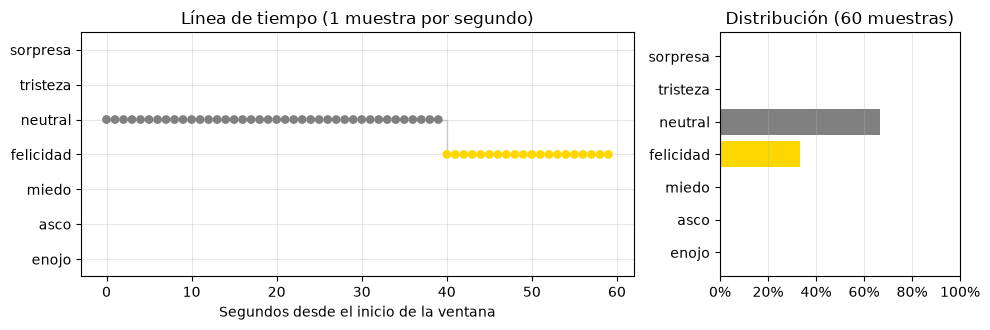

Emoción dominante: neutral (67% del tiempo) | Confianza media: 75% | Muestras: 60 (60 s)


In [6]:
LABELS_ES = [EMOTION_LABELS_ES[c] for c in CLASS_NAMES]
PLOT_COLORS = {c: hex_color(c) for c in CLASS_NAMES}
PLOT_COLORS["neutral"] = "#808080"     # el gris claro de OpenCV casi no se ve sobre fondo blanco


def history_window(history, last_seconds):
    # Muestras del historial dentro de la ventana (None = toda la sesión) como DataFrame.
    df = history.to_dataframe()
    if not df.empty and last_seconds is not None:
        df = df[df["timestamp"] > df["timestamp"].iloc[-1] - last_seconds]
    return df


def plot_history(history, last_seconds=None):
    # Figura con la línea de tiempo y la distribución de emociones de la ventana elegida.
    fig = Figure(figsize=(10, 3.4), dpi=100)
    ax_time, ax_dist = fig.subplots(1, 2, gridspec_kw={"width_ratios": [2.3, 1]})
    df = history_window(history, last_seconds)

    if df.empty:
        for ax in (ax_time, ax_dist):
            ax.set_axis_off()
        ax_time.text(0.5, 0.5, "Aún no hay muestras: activa la cámara y mira de frente",
                     ha="center", va="center", fontsize=12, color="gray", transform=ax_time.transAxes)
        fig.tight_layout()
        return fig

    elapsed = df["timestamp"] - df["timestamp"].iloc[0]
    y = df["emotion"].map(CLASS_NAMES.index)
    ax_time.step(elapsed, y, where="post", color="#d1d5db", linewidth=1, zorder=1)     # conecta los puntos
    ax_time.scatter(elapsed, y, c=[PLOT_COLORS[e] for e in df["emotion"]], s=28, zorder=2)
    ax_time.set_yticks(range(len(CLASS_NAMES)))
    ax_time.set_yticklabels(LABELS_ES)
    ax_time.set_ylim(-0.5, len(CLASS_NAMES) - 0.5)
    ax_time.set_xlabel("Segundos desde el inicio de la ventana")
    ax_time.set_title("Línea de tiempo (1 muestra por segundo)")
    ax_time.grid(alpha=0.3)

    distribution = df["emotion"].value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0)
    ax_dist.barh(LABELS_ES, distribution.values, color=[PLOT_COLORS[c] for c in CLASS_NAMES])
    ax_dist.set_xlim(0, 1)
    ax_dist.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax_dist.set_title(f"Distribución ({len(df)} muestras)")
    ax_dist.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig


def summary_markdown(history, last_seconds=None):
    # Resumen en texto de la ventana (usa summary() de la Fase 3: lo mismo que verá el asistente).
    summary = history.summary(last_seconds=last_seconds)
    if summary["samples"] == 0:
        return "**Resumen:** sin muestras todavía."
    dominant = summary["dominant_emotion"]
    return (f"**Emoción dominante:** {EMOTION_LABELS_ES[dominant]} "
            f"({summary['distribution'][dominant]:.0%} del tiempo)  \n"
            f"**Confianza media:** {summary['mean_confidence_dominant']:.0%}  \n"
            f"**Muestras:** {summary['samples']} ({summary['seconds_covered']:.0f} s)")


# --- Prueba con un historial simulado: 40 s neutral y luego 20 s felicidad ---
rng = np.random.default_rng(42)
simulated_history = EmotionHistory(CLASS_NAMES)
neutral_idx, happy_idx = CLASS_NAMES.index("neutral"), CLASS_NAMES.index("happy")
for second in range(60):
    alpha = np.full(len(CLASS_NAMES), 0.5)
    alpha[neutral_idx if second < 40 else happy_idx] = 8.0
    simulated_history.add(rng.dirichlet(alpha), now=1_000_000 + second)

display(plot_history(simulated_history))
print(summary_markdown(simulated_history).replace("**", "").replace("  \n", " | "))

## Parte 3 · Construir y lanzar la interfaz

### 3.1 Los eventos
- `on_frame(frame)`: recibe cada cuadro de la webcam y devuelve 4 cosas, en el orden de `outputs`: video anotado, tarjeta de la emoción, probabilidades y estado.
- `on_tick(window)`: cada segundo, la gráfica y el resumen del historial de la ventana elegida.
- `on_reset(window)`: borra el historial y las estadísticas.

Si llega un cuadro vacío (`None`, por ejemplo al detener la cámara), `gr.skip()` deja los componentes como estaban.

### 3.2 Espacio para el asistente (Fase 5)
`build_assistant_panel()` crea, por ahora, una sección plegable con un aviso. En el Chat 4 se reemplazará por el chat (`gr.Chatbot`), que leerá `session.history.summary()` para responder cómo se ha sentido la persona. El resto de la interfaz no cambia.

In [7]:
def on_frame(frame):
    # Evento de streaming: un cuadro RGB de la webcam → 4 salidas para la interfaz.
    if frame is None:
        return gr.skip(), gr.skip(), gr.skip(), gr.skip()
    annotated, probs, n_faces = session.process(frame)
    return frame_to_html(annotated), emotion_card_html(probs), probabilities_for_label(probs), status_markdown(n_faces)


def on_tick(window_label):
    # Evento del temporizador: gráfica y resumen del historial.
    last_seconds = WINDOW_CHOICES[window_label]
    return plot_history(session.history, last_seconds), summary_markdown(session.history, last_seconds)


def on_reset(window_label):
    # Botón "Reiniciar historial": borra suavizado, historial y estadísticas.
    session.reset()
    plot, summary = on_tick(window_label)
    return plot, summary, emotion_card_html(None), None


def build_assistant_panel():
    # --- FASE 5 (Chat 4): aquí irá el chat con el asistente (gr.Chatbot + gr.Textbox) ---
    # El asistente usará session.history.summary(last_seconds=...) como contexto.
    with gr.Accordion("💬 Asistente conversacional (Fase 5)", open=False):
        gr.Markdown("Aquí podrás preguntarle al asistente cómo te has sentido. "
                    "Se agrega en la Fase 5.")


CSS = '''
.live-frame {width: 100%; border-radius: 8px; display: block;}
.live-placeholder {height: 300px; display: flex; align-items: center; justify-content: center;
                   text-align: center; padding: 16px; border: 2px dashed #9ca3af; border-radius: 8px; color: #6b7280;}
.emotion-card {border: 3px solid #d1d5db; border-radius: 12px; padding: 14px 16px; text-align: center;}
.emotion-title {font-size: 0.9rem; color: #6b7280; text-transform: uppercase; letter-spacing: 0.05em;}
.emotion-name {font-size: 2.1rem; font-weight: 700; margin: 4px 0;}
.emotion-confidence {font-size: 1.05rem;}
.emotion-hint {font-size: 0.85rem; color: #6b7280;}
.confidence-bar {height: 10px; background: #e5e7eb; border-radius: 5px; margin-top: 8px; overflow: hidden;}
.confidence-bar > div {height: 100%;}
'''

HEADER = '''
# 🎭 Emotion Detection Assistant
Detección de rostros (Haar Cascade) y clasificación de **7 emociones** con una CNN entrenada en FER-2013
(accuracy en test: **66,5 %**). **Cómo usarla:** en el recuadro *Tu cámara* haz clic en **Click to Access Webcam**,
permite el acceso y presiona **Record**.
*El video se procesa solo en este PC y no se guarda; el historial vive en memoria. La expresión facial no
equivale a la emoción real ni es un diagnóstico.*
'''


def build_interface():
    # Arma la página: video + emoción + probabilidades, historial y espacio para el asistente.
    with gr.Blocks(title="Emotion Detection Assistant") as demo:
        gr.Markdown(HEADER)

        # --- Fila 1: cámara | video anotado | emoción y probabilidades ---
        with gr.Row(equal_height=False):
            with gr.Column(scale=3):
                webcam = gr.Image(
                    sources=["webcam"], streaming=True, type="numpy", label="Tu cámara",
                    webcam_options=gr.WebcamOptions(
                        mirror=True,   # efecto espejo (Gradio ya envía el cuadro volteado)
                        constraints={"video": {"width": {"ideal": 640}, "height": {"ideal": 480}}},
                    ),
                )
            with gr.Column(scale=3):
                live_view = gr.HTML(frame_to_html(None), label="Detección en vivo")
            with gr.Column(scale=2):
                emotion_card = gr.HTML(emotion_card_html(None))
                probability_panel = gr.Label(label="Probabilidades (suavizadas, N = 10)",
                                             num_top_classes=len(CLASS_NAMES), show_heading=False)
                status = gr.Markdown("**FPS:** - · **Rostros:** -")

        # --- Fila 2: historial ---
        with gr.Row(equal_height=False):
            with gr.Column(scale=4):
                gr.Markdown("### 📈 Historial de emociones")
                history_plot = gr.Plot(show_label=False, format="png")
            with gr.Column(scale=1, min_width=220):
                window_selector = gr.Radio(list(WINDOW_CHOICES), value="Últimos 30 s", label="Ventana del historial")
                history_summary = gr.Markdown("**Resumen:** sin muestras todavía.")
                reset_button = gr.Button("🔄 Reiniciar historial")

        # --- Fila 3: asistente (Fase 5) ---
        build_assistant_panel()

        # --- Eventos ---
        webcam.stream(
            on_frame, inputs=webcam, outputs=[live_view, emotion_card, probability_panel, status],
            stream_every=STREAM_EVERY, concurrency_limit=1, show_progress="hidden",
        )
        timer = gr.Timer(HISTORY_REFRESH_S)
        timer.tick(on_tick, inputs=window_selector, outputs=[history_plot, history_summary], show_progress="hidden")
        window_selector.change(on_tick, inputs=window_selector, outputs=[history_plot, history_summary],
                               show_progress="hidden")
        reset_button.click(on_reset, inputs=window_selector,
                           outputs=[history_plot, history_summary, emotion_card, probability_panel])
        demo.load(on_tick, inputs=window_selector, outputs=[history_plot, history_summary])
    return demo


print("Interfaz definida")

Interfaz definida


### 3.3 Lanzar la aplicación

Al ejecutar la celda se abre el navegador en `http://127.0.0.1:7860`. Si no se abre solo, copia la dirección que aparece en la salida.

1. En el recuadro **"Tu cámara"** haz clic en **Click to Access Webcam** y permite el acceso cuando el navegador lo pida (los textos de los botones de Gradio vienen en inglés).
2. Presiona **Record**: desde ese momento el navegador empieza a enviar cuadros. Con **Stop** se detiene el envío.
3. Prueba varias expresiones y mira la tarjeta, las barras y la gráfica. Usa varias ventanas del historial.
4. Para la Parte 4, déjala funcionando **al menos 1 minuto** con tu rostro visible.

**Detalles técnicos:**
- En Jupyter, `launch()` **no bloquea** el notebook: el servidor corre en segundo plano y puedes seguir ejecutando celdas.
- `server_name="127.0.0.1"`: solo se puede abrir desde este PC (no desde otros equipos de la red). No se usa `share=True`, que crearía un enlace público en internet.
- `inline=False`: la app no se incrusta en el notebook, así ninguna imagen de la cámara queda guardada en el `.ipynb`.
- `gr.close_all()` cierra un servidor anterior si vuelves a ejecutar la celda. Si el puerto 7860 está ocupado, Gradio usa el siguiente (7861, ...).
- Si la cámara no abre: cierra otras apps que la usen (Zoom, Teams, Cámara, o el notebook 03) y revisa los permisos de cámara del navegador (el ícono a la izquierda de la dirección).

In [8]:
gr.close_all()                 # cierra servidores de Gradio anteriores (si re-ejecutas la celda)
session.reset()                # empieza la sesión de la demo desde cero
demo = build_interface()
_, local_url, _ = demo.launch(
    server_name="127.0.0.1",   # solo accesible desde este PC
    inbrowser=True,            # abre el navegador automáticamente
    inline=False,              # no incrustar en el notebook (privacidad)
    theme=gr.themes.Soft(),
    css=CSS,
    show_error=True,           # si algo falla, el error se ve en la página
)
print(f"App abierta en {local_url} (si el navegador no se abrió, copia esta dirección)")

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
App abierta en http://127.0.0.1:7860/ (si el navegador no se abrió, copia esta dirección)


## Parte 4 · Resultados de la sesión y evidencias

Ejecuta estas celdas **después de usar la app al menos 1 minuto** (no hace falta cerrarla). Si las ejecutas antes, o con *Run All*, solo verás un aviso. Vuelve a ejecutarlas después de usar la app.

### 4.1 Rendimiento de la interfaz
Se miden:
- **FPS de la interfaz:** cuadros por segundo que llegan del navegador. Se excluyen las pausas de más de 1 s (cámara detenida).
- **Tiempo de procesamiento en Python** por cuadro (detección + predicción + suavizado + dibujo), con su percentil 95 (p95: el 95 % de los cuadros tardó eso o menos).
- **Estabilidad:** cambios de etiqueta cada 100 cuadros con rostro, sin suavizar y suavizada (como en la Fase 3).

En la Fase 3 la cámara se leía directamente con OpenCV (16-20 FPS). Aquí cada cuadro además se codifica a JPEG en el navegador, viaja al servidor, se decodifica y la respuesta vuelve. Se espera un FPS algo menor: ese costo extra es la **latencia de red local** de la arquitectura cliente-servidor.

In [9]:
MIN_FRAMES_FOR_RESULTS = 100   # ~1 minuto con la app abierta


def performance_summary(session, skip_frames=10):
    # Resume el rendimiento de la sesión (solo números). Devuelve None si hay muy pocos cuadros.
    processing = np.array(list(session.stats["processing_ms"])[skip_frames:], dtype=float)
    if len(processing) < MIN_FRAMES_FOR_RESULTS:
        return None
    gaps = np.array(list(session.stats["arrival_gap_ms"])[skip_frames:], dtype=float)
    gaps = gaps[gaps <= 1000]                                    # sin pausas largas
    faces = np.array(list(session.stats["faces"])[skip_frames:])
    raw, smoothed = list(session.raw_labels), list(session.smoothed_labels)
    raw_changes, smoothed_changes = count_label_changes(raw), count_label_changes(smoothed)
    return {
        "frames_processed": int(len(processing)),
        "frame_size": list(session.frame_size),
        "stream_every_s": STREAM_EVERY,
        "interface_fps": round(1000 / gaps.mean(), 1) if len(gaps) else None,
        "arrival_gap_ms_p95": round(float(np.percentile(gaps, 95)), 1) if len(gaps) else None,
        "processing_ms_mean": round(float(processing.mean()), 1),
        "processing_ms_p95": round(float(np.percentile(processing, 95)), 1),
        "detection_ms_mean": round(float(np.mean(list(session.stats["detection_ms"])[skip_frames:])), 1),
        "prediction_ms_mean": round(float(np.mean(list(session.stats["prediction_ms"])[skip_frames:])), 1),
        "frames_with_face_ratio": round(float((faces > 0).mean()), 3),
        "frames_with_face": len(raw),
        "smoothing_window": SMOOTHING_WINDOW,
        "raw_changes_per_100_frames": round(100 * raw_changes / len(raw), 2) if raw else None,
        "smoothed_changes_per_100_frames": round(100 * smoothed_changes / len(raw), 2) if raw else None,
        "history_samples": len(session.history.entries),
        "use_tta": detector.use_tta,
    }


gradio_performance = performance_summary(session)
if gradio_performance is None:
    print(f"Todavía hay pocos cuadros ({len(session.stats['processing_ms'])}). "
          "Usa la app al menos 1 minuto y vuelve a ejecutar esta celda.")
else:
    with open(METRICS_DIR / "gradio_performance.json", "w", encoding="utf-8") as f:
        json.dump(gradio_performance, f, indent=2)
    print(json.dumps(gradio_performance, indent=2))
    print("Guardado en reports/metrics/gradio_performance.json (solo números)")

{
  "frames_processed": 1794,
  "frame_size": [
    640,
    480
  ],
  "stream_every_s": 0.05,
  "interface_fps": 12.4,
  "arrival_gap_ms_p95": 136.1,
  "processing_ms_mean": 59.3,
  "processing_ms_p95": 104.2,
  "detection_ms_mean": 23.1,
  "prediction_ms_mean": 32.7,
  "frames_with_face_ratio": 0.938,
  "frames_with_face": 1692,
  "smoothing_window": 10,
  "raw_changes_per_100_frames": 9.69,
  "smoothed_changes_per_100_frames": 3.78,
  "history_samples": 135,
  "use_tta": true
}
Guardado en reports/metrics/gradio_performance.json (solo números)


### 4.2 Historial de la sesión
La gráfica de **toda la sesión** se guarda como evidencia (solo etiquetas, sin imágenes de la cámara). El resumen en JSON es exactamente lo que recibirá el asistente en la Fase 5.

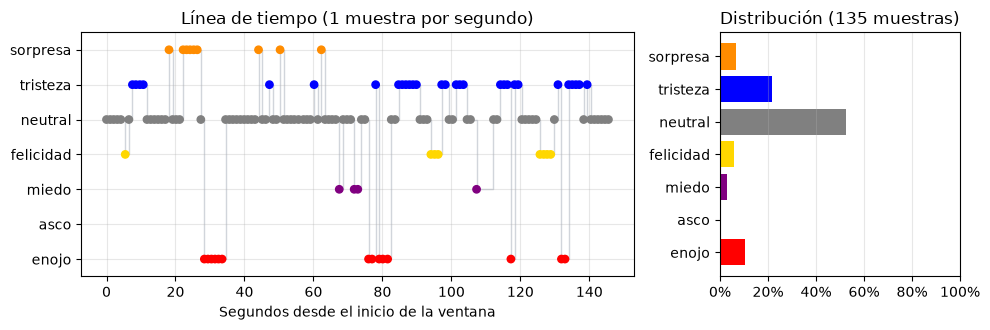

Guardado en reports/figures/gradio_emotion_history.png

Resumen de toda la sesión (entrada del asistente en la Fase 5):
{
  "samples": 135,
  "seconds_covered": 146.5,
  "current_emotion": "neutral",
  "current_confidence": 0.538,
  "dominant_emotion": "neutral",
  "distribution": {
    "angry": 0.104,
    "disgust": 0.0,
    "fear": 0.03,
    "happy": 0.059,
    "neutral": 0.526,
    "sad": 0.215,
    "surprise": 0.067
  },
  "mean_confidence_dominant": 0.522
}

Últimos 30 s:
{
  "samples": 29,
  "seconds_covered": 30.3,
  "current_emotion": "neutral",
  "current_confidence": 0.538,
  "dominant_emotion": "neutral",
  "distribution": {
    "angry": 0.103,
    "disgust": 0.0,
    "fear": 0.0,
    "happy": 0.138,
    "neutral": 0.448,
    "sad": 0.31,
    "surprise": 0.0
  },
  "mean_confidence_dominant": 0.554
}


In [10]:
if len(session.history.entries) < 10:
    print("El historial tiene menos de 10 muestras: usa la app con tu rostro visible y vuelve a ejecutar esta celda.")
else:
    history_figure = plot_history(session.history)
    history_figure.savefig(FIGURES_DIR / "gradio_emotion_history.png", dpi=120)
    display(history_figure)
    print("Guardado en reports/figures/gradio_emotion_history.png")

    print("\nResumen de toda la sesión (entrada del asistente en la Fase 5):")
    print(json.dumps(session.history.summary(), indent=2, ensure_ascii=False))
    print("\nÚltimos 30 s:")
    print(json.dumps(session.history.summary(last_seconds=30), indent=2, ensure_ascii=False))

### 4.3 Apagar el servidor
El servidor sigue encendido mientras el kernel esté activo. Para apagarlo, cambia `STOP_SERVER` a `True` y ejecuta la celda (o usa **Kernel → Shut Down Kernel**). Viene en `False` para que *Run All* no apague la app recién abierta.

In [11]:
STOP_SERVER = False

if STOP_SERVER:
    demo.close()
    print("Servidor de Gradio apagado. La cámara del navegador ya no envía cuadros.")
else:
    print("El servidor sigue encendido (STOP_SERVER = False).")

El servidor sigue encendido (STOP_SERVER = False).


### Evidencias de la Fase 4 para el reporte y el video
- **Capturas de la interfaz** con varias emociones (felicidad, sorpresa, neutral...) donde se vean el video con el recuadro, la tarjeta de la emoción, las barras de probabilidad y la gráfica del historial. Para el reporte puedes usar una sola captura bien iluminada.
- `reports/metrics/gradio_performance.json`: FPS de la interfaz, tiempos de procesamiento y estabilidad. Compáralo con `realtime_performance.json` de la Fase 3 (OpenCV directo frente a la arquitectura cliente-servidor).
- `reports/figures/gradio_emotion_history.png`: historial de una sesión real.
- Captura de esta Parte 4 con el **resumen JSON** (lo que recibirá el asistente).
- Para el video: graba la pantalla mientras usas la app (Win + Alt + R con la Xbox Game Bar) y cambia de expresión; muestra también el selector de ventana del historial.
- **Diagrama de la arquitectura** (Parte 2.1) para el reporte: navegador ↔ servidor local de Gradio ↔ modelo.

**Privacidad antes del commit:** este notebook no muestra imágenes de la cámara (la app no está incrustada), así que no hace falta borrar salidas. La tarjeta de la Parte 2.4 usa probabilidades inventadas y la gráfica de la 2.5 es simulada.